# Tunisia Solar Potential
Irradiation solaire (NASA POWER) par gouvernorat tunisien : classement, courbes mensuelles et petit modèle de prévision.

Exécute les cellules dans l'ordre (Exécution → Tout exécuter).

In [11]:
import requests, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

START, END = 2015, 2024
REGIONS = {  # nom: (latitude, longitude), approximations des chefs-lieux
    "Tozeur": (33.92, 8.13), "Tataouine": (32.93, 10.45), "Gabès": (33.88, 10.10),
    "Sfax": (34.74, 10.76), "Kairouan": (35.68, 10.10), "Tunis": (36.80, 10.18),
    "Bizerte": (37.27, 9.87),
}
URL = "https://power.larc.nasa.gov/api/temporal/monthly/point"

## 1. Récupération des données (API NASA POWER)

In [12]:
rows = []
for name, (lat, lon) in REGIONS.items():
    params = {"parameters": "ALLSKY_SFC_SW_DWN", "community": "RE", "latitude": lat,
              "longitude": lon, "start": START, "end": END, "format": "JSON"}
    r = requests.get(URL, params=params, timeout=60)
    r.raise_for_status()
    series = r.json()["properties"]["parameter"]["ALLSKY_SFC_SW_DWN"]
    for key, value in series.items():
        year, month = int(key[:4]), int(key[4:])
        if 1 <= month <= 12:               # le mois 13 est la moyenne annuelle
            rows.append({"region": name, "year": year, "month": month,
                         "irradiance": np.nan if value == -999 else value})
df = pd.DataFrame(rows)
print(df.shape, "| valeurs manquantes :", df["irradiance"].isna().sum())
df.head()

(840, 4) | valeurs manquantes : 0


,region,year,month,irradiance
0,Tozeur,2015,1,3.3624
1,Tozeur,2015,2,3.9288
2,Tozeur,2015,3,5.3585
3,Tozeur,2015,4,6.5153
4,Tozeur,2015,5,7.3565


## 2. Classement des régions (kWh/m²/jour)

region
Tataouine    5.67
Tozeur       5.47
Gabès        5.34
Kairouan     5.14
Sfax         5.13
Bizerte      4.71
Tunis        4.71
Name: irradiance, dtype: float64


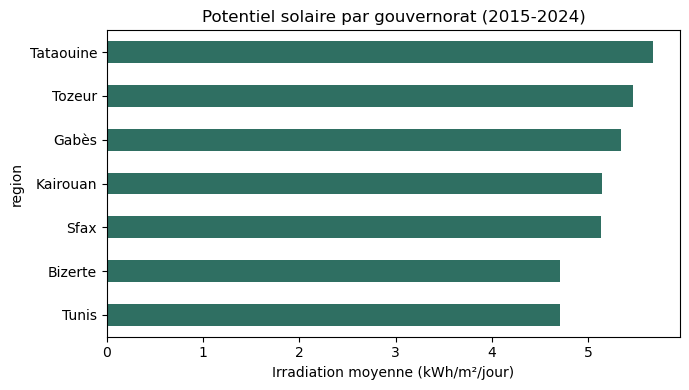

In [13]:
ranking = df.groupby("region")["irradiance"].mean().sort_values(ascending=False).round(2)
print(ranking)
ranking.plot.barh(color="#2f6f62", figsize=(7, 4)).invert_yaxis()
plt.xlabel("Irradiation moyenne (kWh/m²/jour)")
plt.title(f"Potentiel solaire par gouvernorat ({START}-{END})")
plt.tight_layout(); plt.show()

## 3. Profil mensuel

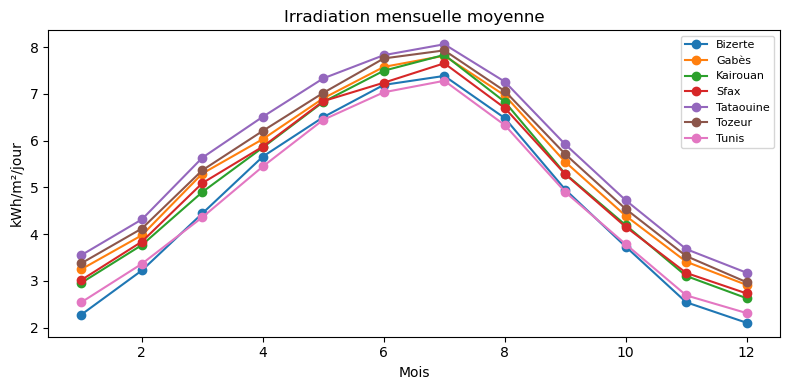

In [14]:
monthly = df.groupby(["region", "month"])["irradiance"].mean().unstack(0)
monthly.plot(figsize=(8, 4), marker="o")
plt.xlabel("Mois"); plt.ylabel("kWh/m²/jour"); plt.title("Irradiation mensuelle moyenne")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

## 4. Modèle de prévision (exemple : Tozeur)
Entraînement sur 2015-2022, test sur 2023-2024. On compare à une référence simple : la moyenne de chaque mois.

In [15]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

d = df[df.region == "Tozeur"].dropna().copy()
d["sin"] = np.sin(2 * np.pi * d["month"] / 12)
d["cos"] = np.cos(2 * np.pi * d["month"] / 12)
train, test = d[d.year <= 2022], d[d.year >= 2023]
feats = ["sin", "cos", "year"]

model = RandomForestRegressor(n_estimators=200, random_state=42).fit(train[feats], train["irradiance"])
pred = model.predict(test[feats])
baseline = test["month"].map(train.groupby("month")["irradiance"].mean())

print("Modèle    MAE:", round(mean_absolute_error(test["irradiance"], pred), 3),
      "| RMSE:", round(mean_squared_error(test["irradiance"], pred) ** 0.5, 3))
print("Référence MAE:", round(mean_absolute_error(test["irradiance"], baseline), 3))

Modèle    MAE: 0.262 | RMSE: 0.33
Référence MAE: 0.204


In [16]:
EMISSION_FACTOR = 0.5    # kg CO2/kWh du réseau tunisien : À REMPLACER par une valeur sourcée
PANEL_EFFICIENCY = 0.18  # rendement typique d'un panneau
PERFORMANCE_RATIO = 0.75 # pertes système (câbles, onduleur, température)

impact = ranking.to_frame("irradiance")
impact["kWh_par_m2_an"] = impact["irradiance"] * 365 * PANEL_EFFICIENCY * PERFORMANCE_RATIO
impact["kgCO2_evites_par_m2_an"] = impact["kWh_par_m2_an"] * EMISSION_FACTOR
print(impact.round(1))

           irradiance  kWh_par_m2_an  kgCO2_evites_par_m2_an
region                                                      
Tataouine         5.7          279.4                   139.7
Tozeur            5.5          269.5                   134.8
Gabès             5.3          263.1                   131.6
Kairouan          5.1          253.3                   126.6
Sfax              5.1          252.8                   126.4
Bizerte           4.7          232.1                   116.0
Tunis             4.7          232.1                   116.0


## 5. Export pour le site web
Télécharge `data.json` et mets-le à côté de `index.html` dans ton dépôt GitHub.

In [22]:
import re, json, os

# Données calculées plus haut dans le notebook
out = []
for name in ranking.index:
    m = monthly[name].round(2).tolist()
    out.append({"name": name, "lat": REGIONS[name][0], "lon": REGIONS[name][1],
                "monthly": m, "annual": round(sum(m) / 12, 2)})
data = {"period": f"{START}-{END}", "unit": "kWh/m²/jour", "regions": out}

# Le fichier doit être dans le même dossier que le notebook
assert os.path.exists("index.html"), f"index.html introuvable dans : {os.getcwd()}"

html = open("index.html", encoding="utf-8").read()
html = re.sub(r'(<script id="embedded-data" type="application/json">).*?(</script>)',
              lambda m: m.group(1) + json.dumps(data, ensure_ascii=False) + m.group(2),
              html, flags=re.S)
open("index.html", "w", encoding="utf-8").write(html)
print("index.html mis à jour dans :", os.getcwd())

index.html mis à jour dans : c:\Users\Sarra\Downloads
